# Fase 3: o que a estrutura relacional revela

O notebook principal mostrou que os perfis existem. Este responde aos itens do enunciado que ainda faltavam:

1. **Comparar as estruturas associadas a cada desfecho, incluindo perfis semelhantes que levam a resultados distintos:** homofilia por desfecho e "gêmeos" (alunos vizinhos no grafo, ou seja, parecidos, que tiveram finais opostos).
2. **O que a representação relacional revela além das variáveis isoladas:** comunidade × melhor variável sozinha, e a combinação de fatores.
3. **Justificar o k:** sensibilidade a k = 20, 40 e 60.
4. **Perfis de sucesso:** as comunidades com menor evasão.

Mesmos dados (Dropout × Graduate, 3.630 alunos), mesmas funções e mesmo grafo do notebook principal (k=40). As partições do Leiden são idênticas às de lá.

In [1]:
# %pip install gower igraph leidenalg torch torch_geometric scikit-learn pandas matplotlib
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gower, igraph as ig, leidenalg as la
import torch, torch.nn.functional as F
from torch_geometric.nn.models import GraphSAGE
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import f1_score, roc_auc_score, normalized_mutual_info_score as NMI
from scipy.stats import chi2_contingency

# ===== PARÂMETROS (iguais para as 4 variações) =====
K = 40                                     # vizinhos do kNN mútuo
JANELAS_RODAR = ["1_matricula", "3_fim_1sem"]
N_PERM = 1000                              # permutações do teste do Leiden
DOBRAS = 5                                 # validação cruzada da GNN
SEED = 42
torch.use_deterministic_algorithms(True); torch.set_num_threads(1)   # GNN reprodutível na mesma máquina
from scipy.stats import wilcoxon
from IPython.display import Image, display
from PIL import Image as PILImage
import os
LARGURA = 6.3
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8})
os.makedirs("figuras", exist_ok=True); os.makedirs("resultados", exist_ok=True)
SLUG = {"Gower": "gower", "Associação": "associacao"}

def salva(fig, nome):
    fig.savefig(f"figuras/{nome}.pdf", bbox_inches="tight", dpi=300)
    fig.savefig(f"figuras/{nome}.png", bbox_inches="tight", dpi=300); plt.close(fig)
    PILImage.open(f"figuras/{nome}.png").convert("RGB").quantize(256, method=PILImage.Quantize.MEDIANCUT).save(f"figuras/{nome}.png", optimize=True)
    display(Image(f"figuras/{nome}.png", width=650))

In [2]:
df = pd.read_csv("data.csv", sep=";")
NOMES = ["marital","app_mode","app_order","course","shift","prev_qual","prev_grade","nationality",
         "mother_qual","father_qual","mother_occ","father_occ","admission_grade","displaced",
         "special_needs","debtor","tuition_ok","gender","scholarship","age","international",
         "s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval",
         "s2_credited","s2_enrolled","s2_evaluations","s2_approved","s2_grade","s2_without_eval",
         "unemployment","inflation","gdp","target"]
df.columns = NOMES
df = df[df.target != "Enrolled"].reset_index(drop=True)      # 2 classes
y = (df.pop("target") == "Dropout").astype(int).values       # 1 = evadiu, 0 = formou
N = len(df)
print(f"{N} alunos | evasão geral = {y.mean():.1%}")

CAT_BASE = ["marital","app_mode","shift","prev_qual","nationality","mother_qual","father_qual",
            "mother_occ","father_occ","displaced","special_needs","gender","international"]
NUM_BASE = ["app_order","prev_grade","admission_grade","age"]
CAT_FIN  = CAT_BASE + ["debtor","tuition_ok","scholarship"]
NUM_S1   = ["s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval"]
NUM_S2   = [c.replace("s1_", "s2_") for c in NUM_S1]
JANELAS = {                                    # (categóricas, numéricas)
    "1_matricula":  (CAT_BASE, NUM_BASE),
    "2_financeiro": (CAT_FIN,  NUM_BASE),
    "3_fim_1sem":   (CAT_FIN,  NUM_BASE + NUM_S1),
    "4_fim_2sem":   (CAT_FIN,  NUM_BASE + NUM_S1 + NUM_S2),
}
# curso e macroeconomia ficam fora da distância; categorias com < 30 alunos viram "outros" (-1)
for c in CAT_FIN:
    vc = df[c].value_counts()
    df[c] = df[c].where(df[c].isin(vc[vc >= 30].index), -1)

3630 alunos | evasão geral = 39.1%


In [3]:
def dist_gower(cats, nums):
    X = pd.concat([df[cats].astype(str), df[nums].astype(float)], axis=1)
    return gower.gower_matrix(X, cat_features=[True] * len(cats) + [False] * len(nums))

def dist_associacao(cats, nums):
    D = np.zeros((N, N))
    # categóricas: perfil de cada categoria nas outras variáveis -> TVD entre perfis
    codes = [pd.Categorical(df[c]).codes for c in cats]
    Q = [c.max() + 1 for c in codes]; pos = np.cumsum([0] + Q); m = len(cats)
    Z = np.zeros((N, sum(Q)))
    for j, c in enumerate(codes): Z[np.arange(N), pos[j] + c] = 1
    ZZ = Z.T @ Z; np.fill_diagonal(ZZ, 0)
    P = ZZ / np.maximum(Z.sum(0)[:, None], 1)
    for j, c in enumerate(codes):
        Pj = P[pos[j]:pos[j + 1]]
        delta = np.abs(Pj[:, None, :] - Pj[None, :, :]).sum(-1) / (2 * (m - 1))
        f = np.bincount(c, minlength=Q[j]) / N
        media = f @ delta @ f
        if media > 0: D += delta[c[:, None], c[None, :]] / media      # comensurável
    # numéricas: padroniza + PCA completo, cada componente dividido pela sua distância média
    X = df[nums].to_numpy(float); X = (X - X.mean(0)) / X.std(0, ddof=1)
    X = X @ np.linalg.svd(X, full_matrices=False)[2].T
    for k in range(X.shape[1]):
        dk = np.abs(X[:, k, None] - X[None, :, k]); D += dk / dk.mean()
    return D.astype(np.float32)

DISTANCIAS = {"Gower": dist_gower, "Associação": dist_associacao}

In [4]:
def knn_mutuo(D, k=K):
    Dm = np.round(D, 6); np.fill_diagonal(Dm, np.inf)       # arredonda: empates exatos em qualquer máquina
    viz = np.argsort(Dm, axis=1, kind="stable")[:, :k]    # empate desfeito pelo índice do aluno
    A = np.zeros((N, N), bool); A[np.repeat(np.arange(N), k), viz.ravel()] = True
    i, j = np.where(np.triu(A & A.T, 1))
    return i, j, np.maximum(1 - D[i, j] / D.max(), 1e-3)

In [5]:
def cramer_v(memb, yy):
    T = pd.crosstab(memb, yy).values
    return np.sqrt(chi2_contingency(T, correction=False)[0] / (T.sum() * (min(T.shape) - 1)))

def roda_leiden(i, j, w):
    g = ig.Graph(n=N, edges=list(zip(i, j))); g.es["weight"] = w
    part = la.find_partition(g, la.ModularityVertexPartition, weights="weight", seed=0)
    memb = np.array(part.membership)
    grandes = np.isin(memb, np.where(np.bincount(memb) >= 30)[0])     # comunidades >= 30 alunos
    mm, yy = memb[grandes], y[grandes]
    v = cramer_v(mm, yy)
    rs = np.random.default_rng(SEED)
    nulo = np.array([cramer_v(mm, rs.permutation(yy)) for _ in range(N_PERM)])
    comp = (pd.DataFrame({"comunidade": mm, "evadiu": yy}).groupby("comunidade")
              .agg(alunos=("evadiu", "size"), evasao=("evadiu", "mean"))
              .sort_values("evasao", ascending=False))
    return dict(memb=memb, comp=comp, modularidade=part.modularity, comunidades=len(comp),
                cobertura=grandes.mean(), V=v, V_max_nulo=nulo.max(),
                p=(1 + (nulo >= v).sum()) / (1 + N_PERM), NMI=NMI(mm, yy))

In [6]:
G = {}                                                    # grafos e partições com k = 40 (iguais ao principal)
for jan in JANELAS_RODAR:
    for dist, fn in DISTANCIAS.items():
        D = fn(*JANELAS[jan]); i, j, w = knn_mutuo(D)
        G[jan, dist] = dict(D=D, i=i, j=j, w=w, leiden=roda_leiden(i, j, w))
        print(f"{jan:12s} {dist:10s} V = {G[jan, dist]['leiden']['V']:.3f}  ({G[jan, dist]['leiden']['comunidades']} comunidades)")

1_matricula  Gower      V = 0.316  (12 comunidades)


1_matricula  Associação V = 0.332  (16 comunidades)


3_fim_1sem   Gower      V = 0.463  (11 comunidades)


3_fim_1sem   Associação V = 0.576  (18 comunidades)


## 1. A estrutura de cada desfecho: homofilia

Se o desfecho fosse sorteado, a fração de arestas ligando alunos **com o mesmo desfecho** seria p² + (1−p)² ≈ 52%. Quanto mais acima disso, mais os desfechos "moram juntos" no grafo, mesmo que o grafo não tenha visto o desfecho.

Para cada desfecho:
- **vizinhos com o mesmo desfecho:** entre os vizinhos de quem evadiu, quantos também evadiram (contra 39% esperados); entre os vizinhos de quem se formou, quantos também se formaram (contra 61% esperados);
- **"isolados no próprio desfecho":** alunos cuja vizinhança é 70% ou mais do desfecho **oposto**. São os casos "o perfil dizia uma coisa e aconteceu outra".

In [7]:
lin = []
for (jan, dist), g in G.items():
    i, j = g["i"], g["j"]; p = y.mean()
    viz_evadiu = np.bincount(np.r_[i, j], weights=np.r_[y[j], y[i]], minlength=N)        # nº de vizinhos que evadiram
    grau = np.bincount(np.r_[i, j], minlength=N); tem = grau > 0
    frac = np.divide(viz_evadiu, grau, out=np.full(N, np.nan), where=tem)               # fração de vizinhos que evadiram
    gg = ig.Graph(n=N, edges=list(zip(i, j)))
    lin.append({"janela": jan, "distância": dist,
                "arestas mesmo desfecho": (y[i] == y[j]).mean(), "esperado ao acaso": p**2 + (1 - p)**2,
                "assortatividade": gg.assortativity_nominal(list(y), directed=False),
                "evadiu: vizinhos que evadiram": np.nanmean(frac[(y == 1) & tem]),
                "formou: vizinhos que se formaram": 1 - np.nanmean(frac[(y == 0) & tem]),
                "evadiu cercado de formados (≥70%)": int(((y == 1) & tem & (frac <= 0.3)).sum()),
                "formou cercado de evadidos (≥70%)": int(((y == 0) & tem & (frac >= 0.7)).sum()),
                "grau médio evadiu": grau[y == 1].mean(), "grau médio formou": grau[y == 0].mean()})
    g["frac_viz_evadiu"] = frac
homof = pd.DataFrame(lin).round(3); homof.to_csv("resultados/homofilia.csv", index=False); display(homof)

,janela,distância,arestas mesmo desfecho,esperado ao acaso,assortatividade,evadiu: vizinhos que evadiram,formou: vizinhos que se formaram,evadiu cercado de formados (≥70%),formou cercado de evadidos (≥70%),grau médio evadiu,grau médio formou
0,1_matricula,Gower,0.611,0.524,0.161,0.489,0.672,336,123,20.567,22.967
1,1_matricula,Associação,0.610,0.524,0.166,0.486,0.673,340,132,21.871,23.724
2,3_fim_1sem,Gower,0.733,0.524,0.408,0.642,0.774,239,66,18.100,22.144
3,3_fim_1sem,Associação,0.781,0.524,0.519,0.708,0.811,199,48,18.138,21.437


## 2. Gêmeos com destinos diferentes

No grafo da **matrícula**, cada aresta liga dois alunos que eram muito parecidos **no primeiro dia** (estão entre os 40 mais parecidos um do outro). Separamos as arestas cujos dois alunos tiveram **finais opostos**: um evadiu, o outro se formou. São os "gêmeos com destinos diferentes".

A pergunta é: **o que separou esses gêmeos?** Comparamos, dentro de cada par, variáveis que **não** estavam no grafo da matrícula: o desempenho e a situação financeira do 1º semestre. Por construção, as variáveis da matrícula devem quase não diferir dentro do par. A tabela confere isso nas linhas "(controle)".

Teste estatístico: Wilcoxon pareado (o par é a unidade). **Ressalvas:** (1) um aluno aparece em vários pares, então os pares não são independentes e o p-valor é otimista; o que importa é o tamanho da diferença. (2) Parte da diferença no 1º semestre pode ser o próprio abandono acontecendo (quem para de frequentar não é aprovado). Mesmo assim, é o **primeiro sinal observável** que separa alunos que eram parecidos na entrada, e é por ele que o acompanhamento deve começar.

In [8]:
DEPOIS = {"1º sem: disciplinas aprovadas": ("s1_approved", "num"), "1º sem: nota média": ("s1_grade", "num"),
          "1º sem: avaliações feitas": ("s1_evaluations", "num"), "1º sem: inscritas sem avaliação": ("s1_without_eval", "num"),
          "mensalidade atrasada": ("tuition_ok", 0), "devedor": ("debtor", 1), "bolsista": ("scholarship", 1),
          "2º sem: disciplinas aprovadas": ("s2_approved", "num")}
CONTROLE = {"idade (controle)": ("age", "num"), "nota de admissão (controle)": ("admission_grade", "num")}

def valor(nome, spec):
    v, t = spec
    return df[v].to_numpy(float) if t == "num" else (df[v] == t).to_numpy(float)

gemeos = {}
for dist in DISTANCIAS:
    g = G["1_matricula", dist]; i, j = g["i"], g["j"]
    disc = y[i] != y[j]
    ev = np.where(y[i] == 1, i, j)[disc]; fo = np.where(y[i] == 1, j, i)[disc]       # em cada par: quem evadiu, quem formou
    lin = []
    for nome, spec in {**CONTROLE, **DEPOIS}.items():
        a, b = valor(nome, spec)[ev], valor(nome, spec)[fo]
        bin_ = spec[1] != "num"
        lin.append({"variável": nome, "gêmeo que evadiu": a.mean() * (100 if bin_ else 1), "gêmeo que se formou": b.mean() * (100 if bin_ else 1),
                    "unidade": "%" if bin_ else "média",
                    "pares em que o que evadiu está pior": np.mean(a > b) if nome.startswith(("mensalidade", "devedor", "1º sem: inscritas")) else np.mean(a < b),
                    "p (Wilcoxon)": wilcoxon(a, b).pvalue if np.any(a != b) else 1.0})
    t = pd.DataFrame(lin)
    gemeos[dist] = dict(tab=t, n_pares=int(disc.sum()), frac=disc.mean())
    print(f"\n=== {dist}: {disc.sum()} pares de gêmeos com destinos diferentes ({disc.mean():.0%} das arestas da matrícula)")
    display(t.round(3))
pd.concat([v["tab"].assign(distancia=d, n_pares=v["n_pares"]) for d, v in gemeos.items()]).round(4).to_csv("resultados/gemeos.csv", index=False)


=== Gower: 15560 pares de gêmeos com destinos diferentes (39% das arestas da matrícula)


,variável,gêmeo que evadiu,gêmeo que se formou,unidade,pares em que o que evadiu está pior,p (Wilcoxon)
0,idade (controle),23.540,23.014,média,0.341,0.0
1,nota de admissão (controle),125.315,127.731,média,0.546,0.0
2,1º sem: disciplinas aprovadas,2.739,6.247,média,0.804,0.0
3,1º sem: nota média,7.746,12.574,média,0.780,0.0
4,1º sem: avaliações feitas,7.445,8.377,média,0.471,0.0
5,1º sem: inscritas sem avaliação,0.157,0.074,média,0.073,0.0
6,mensalidade atrasada,29.120,1.150,%,0.288,0.0
7,devedor,20.990,3.940,%,0.200,0.0
8,bolsista,12.963,34.402,%,0.288,0.0
9,2º sem: disciplinas aprovadas,2.091,6.136,média,0.848,0.0



=== Associação: 16268 pares de gêmeos com destinos diferentes (39% das arestas da matrícula)


,variável,gêmeo que evadiu,gêmeo que se formou,unidade,pares em que o que evadiu está pior,p (Wilcoxon)
0,idade (controle),24.158,23.568,média,0.333,0.0
1,nota de admissão (controle),125.812,127.378,média,0.530,0.0
2,1º sem: disciplinas aprovadas,2.769,6.303,média,0.806,0.0
3,1º sem: nota média,7.805,12.568,média,0.783,0.0
4,1º sem: avaliações feitas,7.529,8.499,média,0.472,0.0
5,1º sem: inscritas sem avaliação,0.145,0.086,média,0.068,0.0
6,mensalidade atrasada,30.139,1.438,%,0.296,0.0
7,devedor,22.056,4.586,%,0.208,0.0
8,bolsista,12.245,35.081,%,0.297,0.0
9,2º sem: disciplinas aprovadas,2.157,6.176,média,0.848,0.0


### Figura 11: o que separou os gêmeos
Em cada par de gêmeos (parecidos na matrícula, destinos opostos), a média do que evadiu (vermelho) contra a do que se formou (verde). As variáveis estão padronizadas (desvios-padrão da média geral) para caberem no mesmo eixo. As duas primeiras linhas são o controle: são iguais porque os alunos eram parecidos na matrícula.

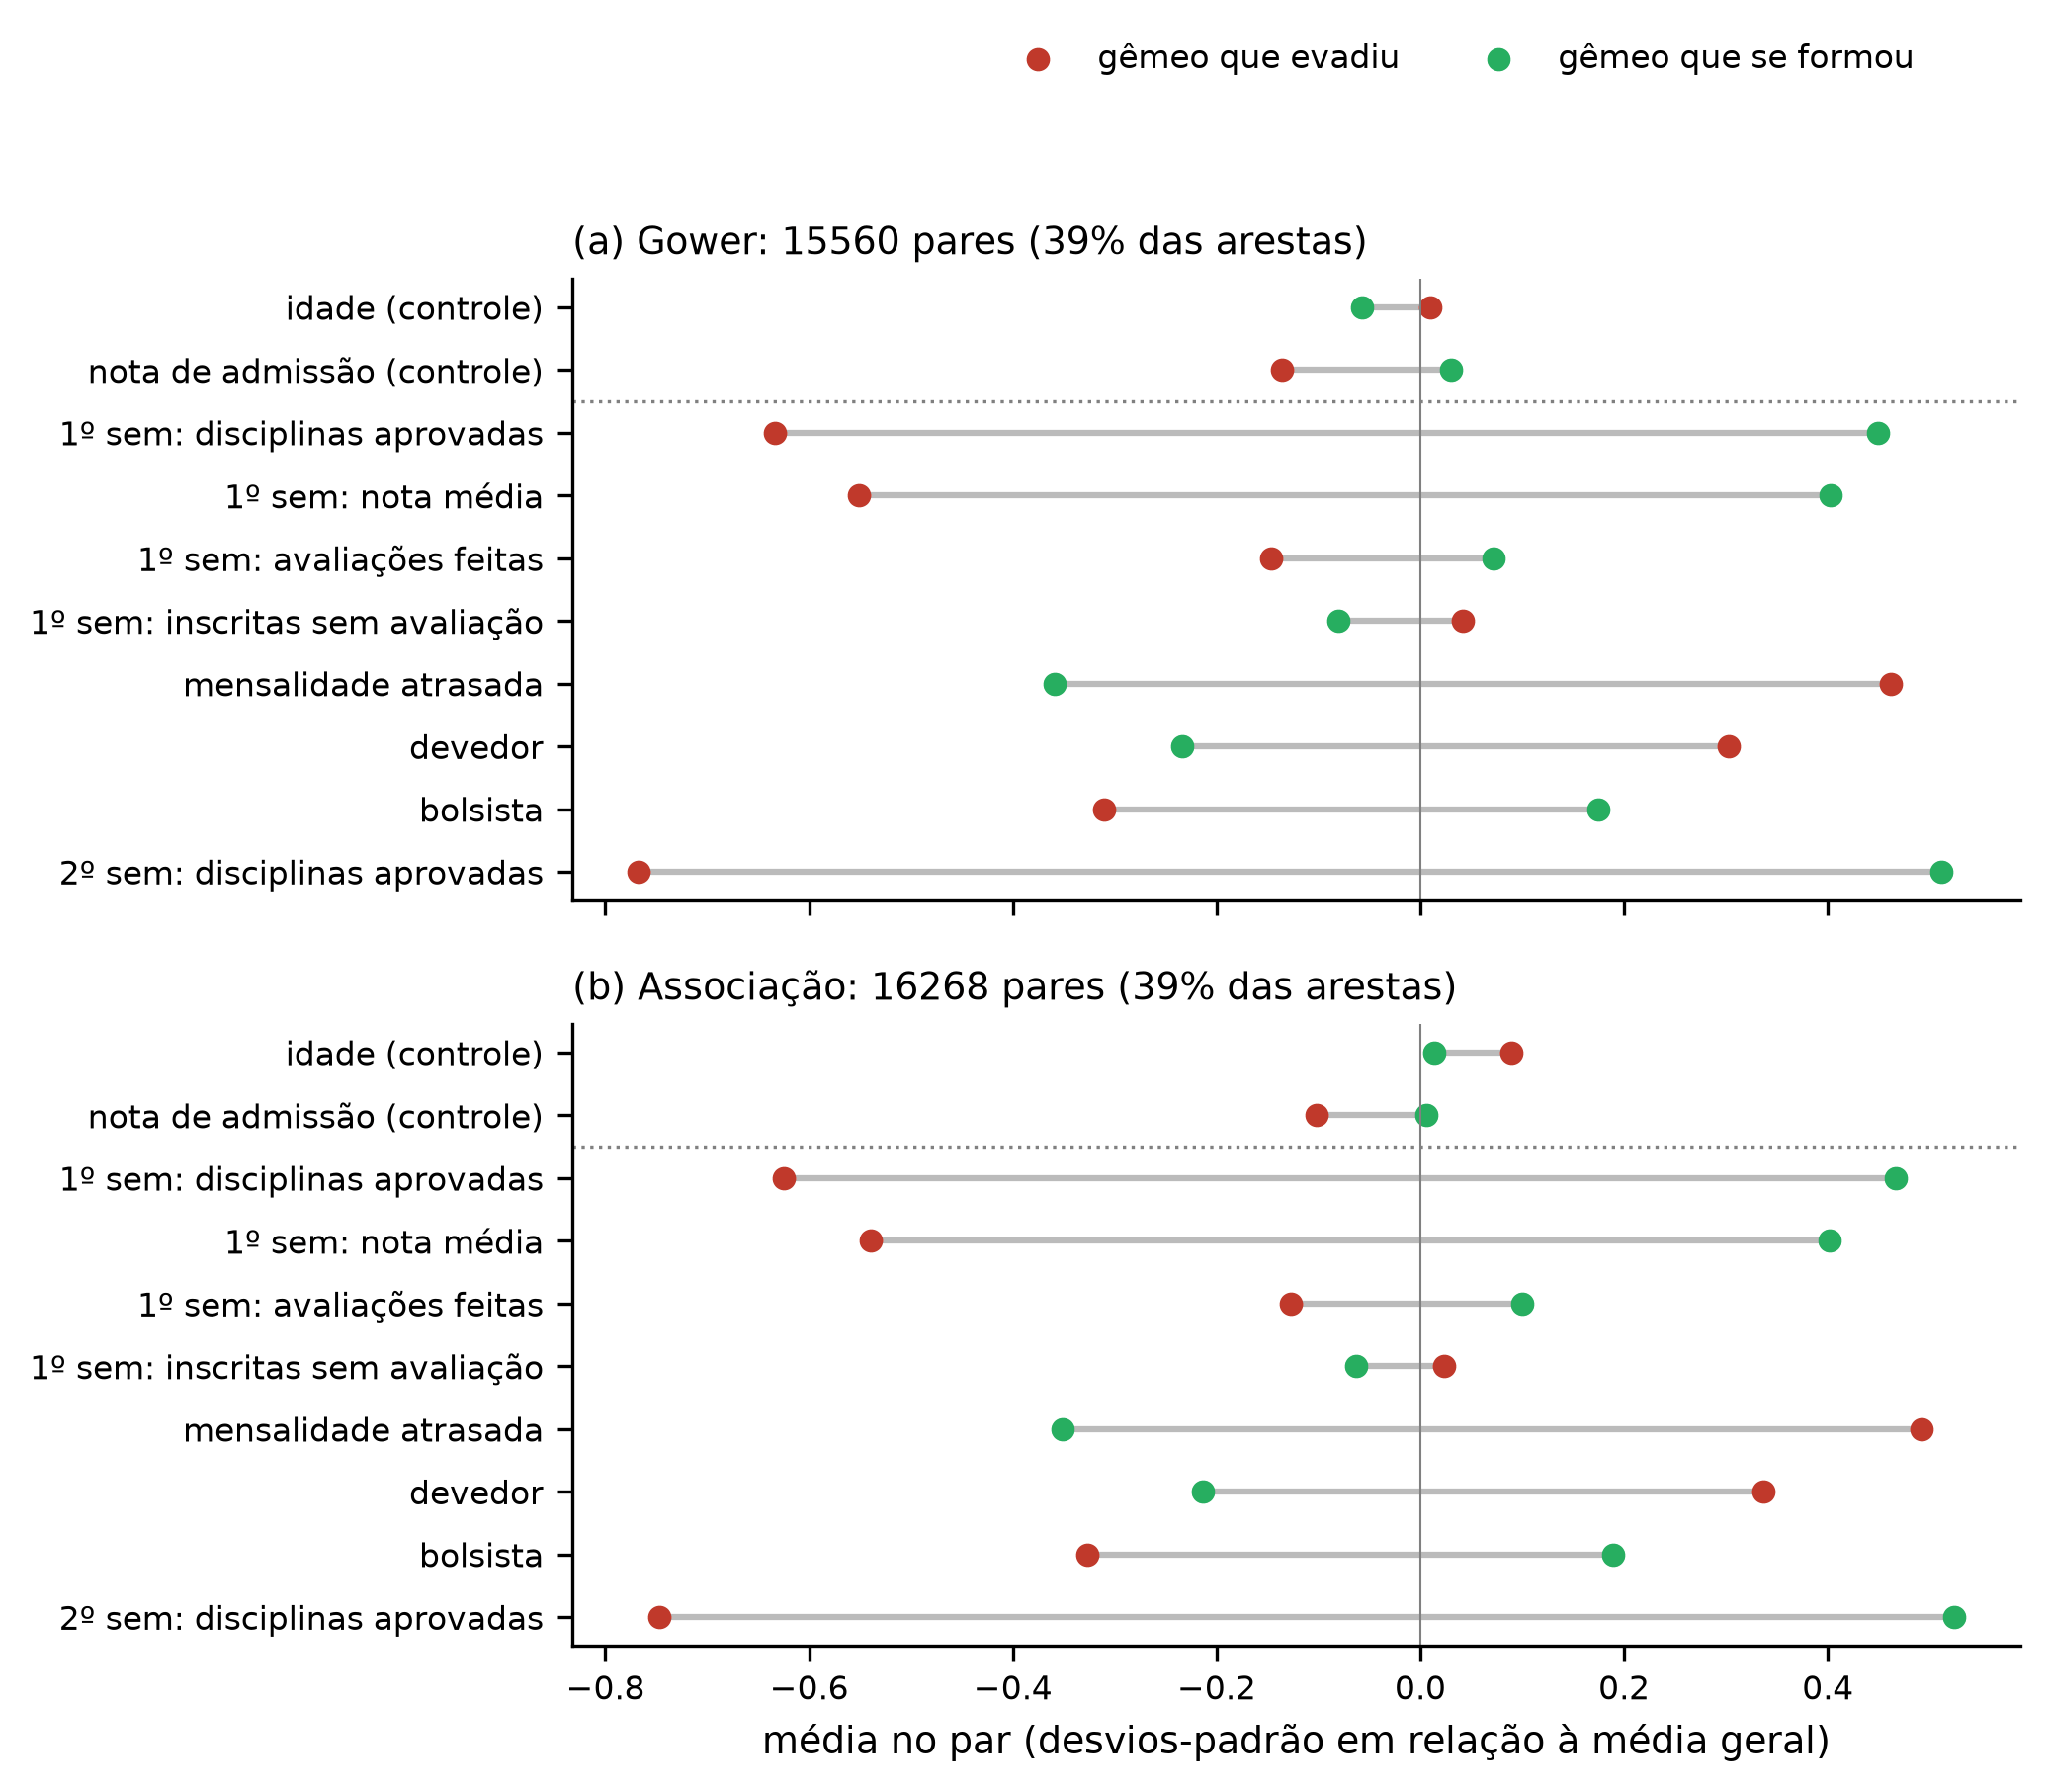

In [9]:
fig, axs = plt.subplots(2, 1, figsize=(LARGURA, LARGURA * 0.95), sharex=True)
nomes = list(CONTROLE) + list(DEPOIS)
for ax, dist, letra in zip(axs, DISTANCIAS, "ab"):
    g = G["1_matricula", dist]; i, j = g["i"], g["j"]; disc = y[i] != y[j]
    ev = np.where(y[i] == 1, i, j)[disc]; fo = np.where(y[i] == 1, j, i)[disc]
    for k, nome in enumerate(nomes):
        v = valor(nome, {**CONTROLE, **DEPOIS}[nome]); z = (v - v.mean()) / v.std()
        a, b = z[ev].mean(), z[fo].mean()
        ax.plot([a, b], [k, k], c="#bbbbbb", lw=1.5, zorder=1)
        ax.scatter([a], [k], c="#c0392b", s=22, zorder=2, label="gêmeo que evadiu" if k == 0 else None)
        ax.scatter([b], [k], c="#27ae60", s=22, zorder=2, label="gêmeo que se formou" if k == 0 else None)
    ax.axhline(len(CONTROLE) - 0.5, c="gray", ls=":", lw=0.8)
    ax.set_yticks(range(len(nomes)), nomes); ax.invert_yaxis(); ax.axvline(0, c="gray", lw=0.5)
    ax.set_title(f"({letra}) {dist}: {gemeos[dist]['n_pares']} pares ({gemeos[dist]['frac']:.0%} das arestas)", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
axs[1].set_xlabel("média no par (desvios-padrão em relação à média geral)")
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.6, 1.03))
salva(fig, "11_gemeos_destinos_diferentes")

## 3. O grafo revela mais que as variáveis isoladas?

**(a) Separação.** Comparamos o V de Cramér da **comunidade** com o de **cada variável sozinha** (numéricas divididas em quintis). É a pergunta "quanto cada fator pesa", que os relatórios tradicionais respondem.

**(b) Quem é o grupo de risco.** Um ranking de variáveis diz quanto cada uma pesa *em média*, mas não *quem* são os alunos de risco. Um grupo pequeno e de risco altíssimo pode ficar diluído numa variável com muitas categorias. Verificamos isso com o grupo de maior risco da matrícula.

In [10]:
def v_variavel(v, cat):
    x = df[v] if cat else pd.qcut(df[v].rank(method="first"), 5, labels=False)
    return cramer_v(x.to_numpy(), y)

iso = {}
for jan in JANELAS_RODAR:
    cats, nums = JANELAS[jan]
    s = pd.Series({**{c: v_variavel(c, True) for c in cats}, **{c: v_variavel(c, False) for c in nums}}).sort_values(ascending=False)
    iso[jan] = s
    print(f"\n=== {jan}: comunidade Gower V = {G[jan, 'Gower']['leiden']['V']:.3f} | Associação V = {G[jan, 'Associação']['leiden']['V']:.3f}")
    print("5 melhores variáveis isoladas:"); display(s.head(5).round(3).to_frame("V de Cramér"))
pd.concat([s.rename("V").to_frame().assign(janela=j) for j, s in iso.items()]).round(4).to_csv("resultados/variaveis_isoladas.csv")


=== 1_matricula: comunidade Gower V = 0.316 | Associação V = 0.332
5 melhores variáveis isoladas:


,V de Cramér
age,0.331
app_mode,0.325
gender,0.252
prev_grade,0.196
mother_qual,0.191



=== 3_fim_1sem: comunidade Gower V = 0.463 | Associação V = 0.576
5 melhores variáveis isoladas:


,V de Cramér
s1_approved,0.647
s1_grade,0.554
tuition_ok,0.442
age,0.331
app_mode,0.325


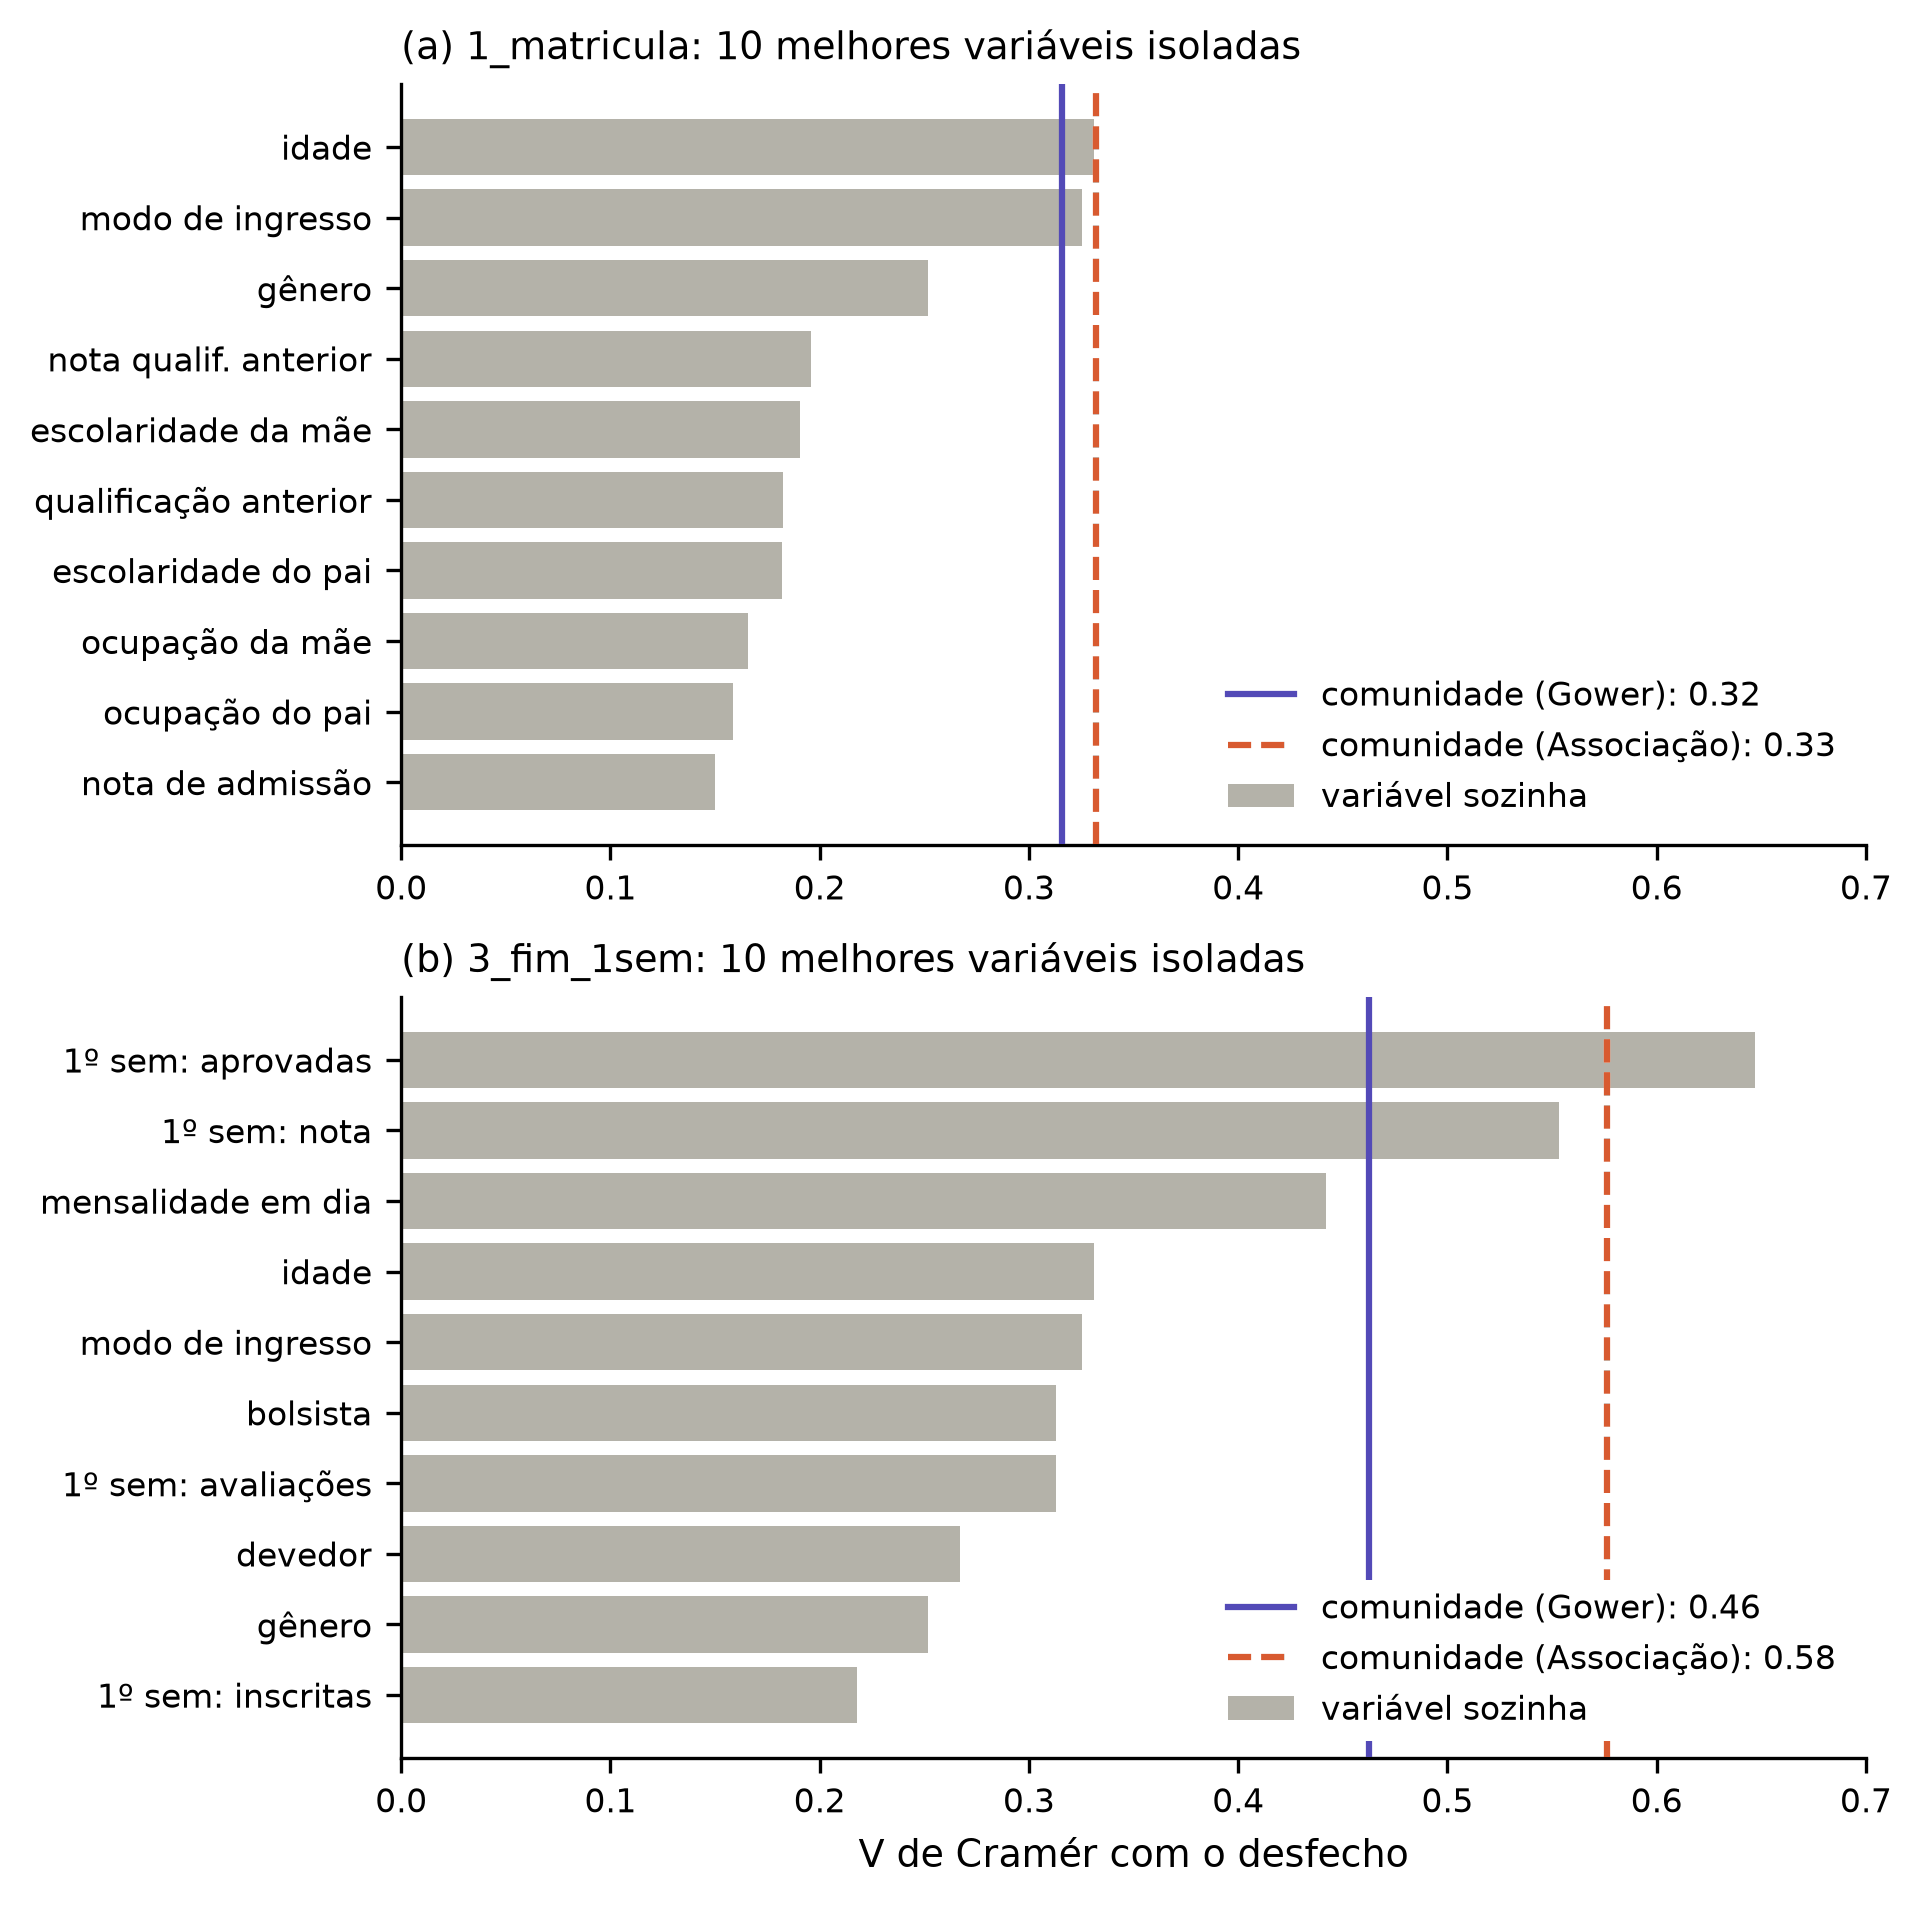

In [11]:
NOME_VAR = {"marital": "estado civil", "app_mode": "modo de ingresso", "shift": "turno", "prev_qual": "qualificação anterior",
            "nationality": "nacionalidade", "mother_qual": "escolaridade da mãe", "father_qual": "escolaridade do pai",
            "mother_occ": "ocupação da mãe", "father_occ": "ocupação do pai", "displaced": "deslocado", "special_needs": "nec. especiais",
            "gender": "gênero", "international": "internacional", "debtor": "devedor", "tuition_ok": "mensalidade em dia",
            "scholarship": "bolsista", "app_order": "ordem de candidatura", "prev_grade": "nota qualif. anterior",
            "admission_grade": "nota de admissão", "age": "idade", "s1_credited": "1º sem: creditadas", "s1_enrolled": "1º sem: inscritas",
            "s1_evaluations": "1º sem: avaliações", "s1_approved": "1º sem: aprovadas", "s1_grade": "1º sem: nota", "s1_without_eval": "1º sem: sem avaliação"}
fig, axs = plt.subplots(2, 1, figsize=(LARGURA, LARGURA * 1.15))
for ax, jan, letra in zip(axs, JANELAS_RODAR, "ab"):
    s = iso[jan].head(10)[::-1]
    ax.barh([NOME_VAR[c] for c in s.index], s.values, color="#B4B2A9", label="variável sozinha")
    for dist, ls in [("Gower", "-"), ("Associação", "--")]:
        ax.axvline(G[jan, dist]["leiden"]["V"], c="#534AB7" if dist == "Gower" else "#D85A30", ls=ls, lw=1.5,
                   label=f"comunidade ({dist}): {G[jan, dist]['leiden']['V']:.2f}")
    ax.set_title(f"({letra}) {jan}: 10 melhores variáveis isoladas", loc="left"); ax.set_xlim(0, 0.7)
    ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=True, framealpha=1, edgecolor="none", loc="lower right")
axs[1].set_xlabel("V de Cramér com o desfecho")
salva(fig, "12_comunidade_vs_variaveis_isoladas")

In [12]:
pais = ((df.mother_qual == 34) | (df.father_qual == 34)).to_numpy()
velho = (df.age >= 25).to_numpy()
combo = pd.DataFrame({"pais com escolaridade desconhecida": np.where(pais, "sim", "não"), "idade ≥ 25": np.where(velho, "sim", "não"), "evadiu": y})
t2 = combo.groupby(["pais com escolaridade desconhecida", "idade ≥ 25"])["evadiu"].agg(alunos="size", evasao="mean").round(3)
t2.to_csv("resultados/combinacao_fatores.csv"); display(t2)
r = G["1_matricula", "Gower"]["leiden"]; c_top = r["comp"].index[0]; m = r["memb"] == c_top
print(f"Comunidade de maior risco (Gower, matrícula): {m.sum()} alunos, evasão {y[m].mean():.0%} | "
      f"{pais[m].mean():.0%} com pais de escolaridade desconhecida, {velho[m].mean():.0%} com 25+ anos")

alunos  evasao
pais com escolaridade desconhecida idade ≥ 25                
não                                não           2601   0.289
                                   sim            890   0.636
sim                                não             53   0.717
                                   sim             86   0.756

Comunidade de maior risco (Gower, matrícula): 142 alunos, evasão 70% | 83% com pais de escolaridade desconhecida, 61% com 25+ anos


### Figura 13: os fatores do grupo de maior risco
Evasão por combinação dos dois fatores que caracterizam a comunidade de maior risco da matrícula. A linha pontilhada é a evasão geral. Cada fator sozinho já eleva muito o risco. O grupo com pais de escolaridade desconhecida é pequeno (≈ 4% dos alunos), por isso a escolaridade dos pais aparece só no meio do ranking de variáveis da figura 12. O grafo encontrou esse grupo sem que ninguém indicasse quais variáveis olhar.

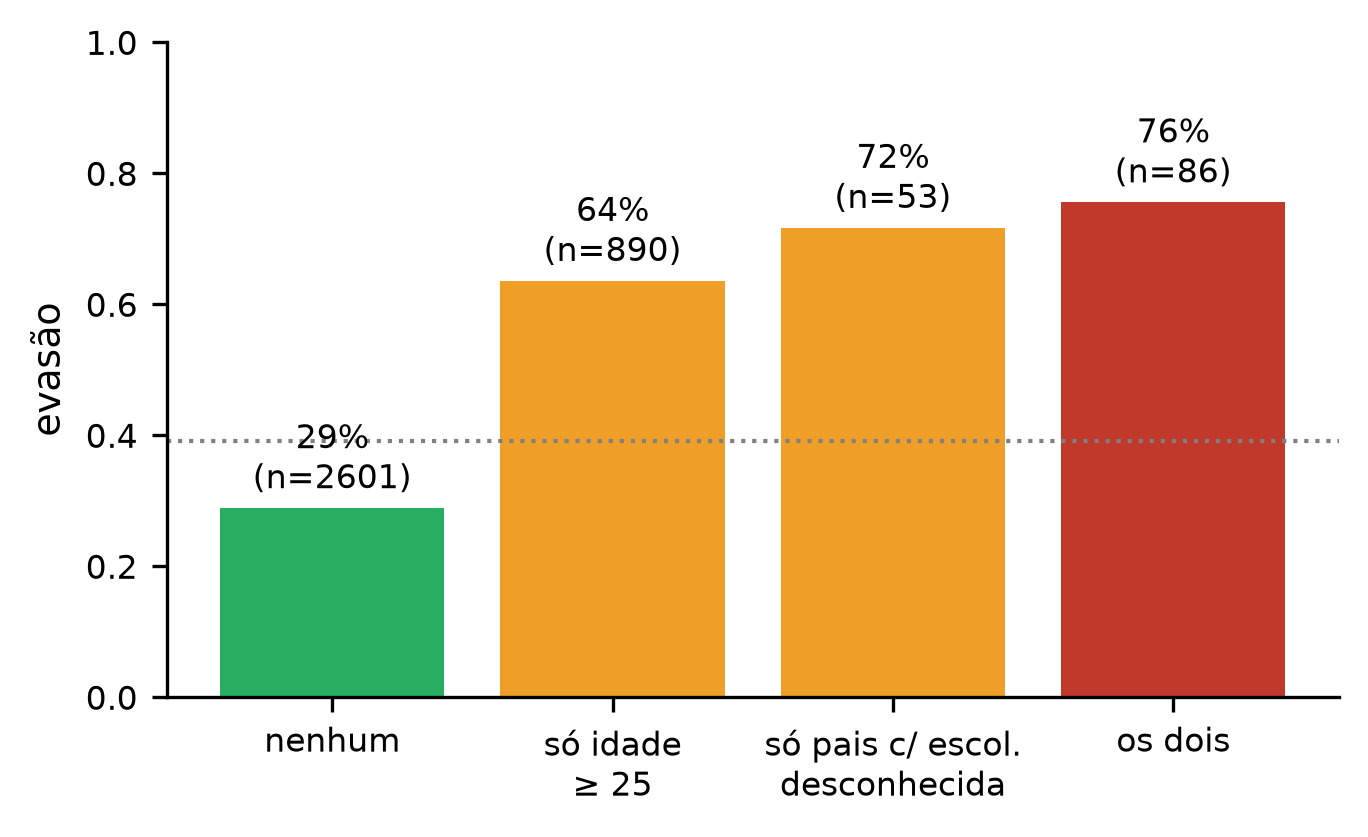

In [13]:
fig, ax = plt.subplots(figsize=(LARGURA * 0.8, LARGURA * 0.45))
ordem = [("não", "não"), ("não", "sim"), ("sim", "não"), ("sim", "sim")]
rot = ["nenhum", "só idade\n≥ 25", "só pais c/ escol.\ndesconhecida", "os dois"]
vals = [t2.loc[o, "evasao"] for o in ordem]; ns = [int(t2.loc[o, "alunos"]) for o in ordem]
b = ax.bar(rot, vals, color=["#27ae60", "#EF9F27", "#EF9F27", "#c0392b"])
ax.bar_label(b, labels=[f"{v:.0%}\n(n={n})" for v, n in zip(vals, ns)], fontsize=8, padding=2)
ax.axhline(y.mean(), c="gray", ls=":", lw=1); ax.set_ylim(0, 1); ax.set_ylabel("evasão")
ax.spines[["top", "right"]].set_visible(False)
salva(fig, "13_combinacao_de_fatores")

## 4. Sensibilidade ao k

O grafo usa k = 40. Repetimos o Leiden com k = 20 e k = 60. Se o V de Cramér e o grupo de maior risco se mantêm, a conclusão não depende da escolha do k. **NMI com k=40** mede o quanto a partição é parecida com a principal (1 = idêntica).

In [14]:
N_PERM = 200                                              # menos permutações aqui: só para confirmar p < 0,01
lin = []
for jan in JANELAS_RODAR:
    for dist in DISTANCIAS:
        D = G[jan, dist]["D"]; base40 = G[jan, dist]["leiden"]["memb"]
        for k in [20, 40, 60]:
            r = G[jan, dist]["leiden"] if k == 40 else roda_leiden(*knn_mutuo(D, k))
            lin.append({"janela": jan, "distância": dist, "k": k, "V de Cramér": r["V"], "p": r["p"] if k != 40 else G[jan, dist]["leiden"]["p"],
                        "comunidades ≥30": r["comunidades"], "maior evasão numa comunidade": r["comp"].evasao.max(),
                        "NMI com k=40": NMI(base40, r["memb"])})
sens = pd.DataFrame(lin).round(3); sens.to_csv("resultados/sensibilidade_k.csv", index=False); display(sens)

,janela,distância,k,V de Cramér,p,comunidades ≥30,maior evasão numa comunidade,NMI com k=40
0,1_matricula,Gower,20,0.322,0.005,14,0.678,0.642
1,1_matricula,Gower,40,0.316,0.001,12,0.697,1.000
2,1_matricula,Gower,60,0.316,0.005,10,0.686,0.777
3,1_matricula,Associação,20,0.363,0.005,19,0.807,0.847
4,1_matricula,Associação,40,0.332,0.001,16,0.669,1.000
5,1_matricula,Associação,60,0.343,0.005,15,0.671,0.925
6,3_fim_1sem,Gower,20,0.495,0.005,15,0.912,0.593
7,3_fim_1sem,Gower,40,0.463,0.001,11,0.828,1.000
8,3_fim_1sem,Gower,60,0.469,0.005,10,0.927,0.653
9,3_fim_1sem,Associação,20,0.589,0.005,21,0.995,0.832


## 5. Perfis de sucesso

As 3 comunidades de **menor** evasão em cada variação, com o que as caracteriza: numéricas em desvios-padrão da média geral, e categorias presentes em 50% ou mais da comunidade e pelo menos 1,3× mais comuns que na base.

In [15]:
pd.set_option("display.max_colwidth", None)
ROTCAT = {("app_mode", 39): "ingresso maiores de 23", ("app_mode", 1): "1ª fase geral", ("app_mode", 17): "2ª fase geral",
          ("app_mode", 7): "já tem curso superior", ("mother_qual", 34): "mãe: escol. desconhecida", ("father_qual", 34): "pai: escol. desconhecida",
          ("debtor", 1): "devedor", ("tuition_ok", 0): "mensalidade atrasada", ("scholarship", 1): "bolsista", ("displaced", 1): "deslocado",
          ("gender", 0): "mulher", ("gender", 1): "homem", ("marital", 1): "solteiro(a)", ("marital", 2): "casado(a)", ("shift", 1): "diurno", ("shift", 0): "noturno", ("displaced", 0): "não deslocado", ("scholarship", 0): "não bolsista",
          ("mother_occ", 9): "mãe: trabalho não qualificado", ("father_occ", 9): "pai: trabalho não qualificado"}
def perfil(jan, dist, comunidades):
    cats, nums = JANELAS[jan]; r = G[jan, dist]["leiden"]; z = (df[nums] - df[nums].mean()) / df[nums].std(); out = []
    for c in comunidades:
        m = r["memb"] == c; zc = z[m].mean(); zc = zc[zc.abs().sort_values(ascending=False).index[:3]]
        dom = []
        for v in cats:
            for val, sh in df.loc[m, v].value_counts(normalize=True).items():
                lift = sh / (df[v] == val).mean()
                if sh >= 0.5 and lift >= 1.3: dom.append((f"{ROTCAT.get((v, val), f'{v}={val}')} ({sh:.0%}, ×{lift:.1f})", sh))
        out.append({"comunidade": f"C{c}", "alunos": int(m.sum()), "evasão": f"{y[m].mean():.0%}",
                    "numéricas": "; ".join(f"{NOME_VAR[k]} {v:+.1f} dp" for k, v in zc.items()),
                    "categorias marcantes": "; ".join(t for t, _ in sorted(dom, key=lambda t: -t[1])[:3]) or "—"})
    return pd.DataFrame(out)

suc = []
for jan in JANELAS_RODAR:
    for dist in DISTANCIAS:
        t = perfil(jan, dist, G[jan, dist]["leiden"]["comp"].index[::-1][:3]).assign(janela=jan, distancia=dist)
        suc.append(t); print(f"\n--- {dist} · {jan}: 3 comunidades de MENOR evasão"); display(t.drop(columns=["janela", "distancia"]))
pd.concat(suc).to_csv("resultados/perfis_sucesso.csv", index=False)


--- Gower · 1_matricula: 3 comunidades de MENOR evasão


,comunidade,alunos,evasão,numéricas,categorias marcantes
0,C6,325,19%,idade -0.5 dp; ordem de candidatura +0.4 dp; nota qualif. anterior -0.1 dp,"deslocado (100%, ×1.8); mulher (100%, ×1.5); 1ª fase geral (81%, ×2.1)"
1,C3,421,23%,ordem de candidatura +0.7 dp; idade -0.6 dp; nota de admissão -0.2 dp,"deslocado (100%, ×1.8); mulher (100%, ×1.5); 2ª fase geral (59%, ×3.0)"
2,C5,347,26%,idade -0.5 dp; ordem de candidatura +0.3 dp; nota qualif. anterior +0.1 dp,"deslocado (100%, ×1.8); mãe: trabalho não qualificado (95%, ×2.6); 1ª fase geral (68%, ×1.8)"



--- Associação · 1_matricula: 3 comunidades de MENOR evasão


,comunidade,alunos,evasão,numéricas,categorias marcantes
0,C1,406,19%,ordem de candidatura +1.9 dp; idade -0.6 dp; nota de admissão -0.1 dp,"deslocado (100%, ×1.8); mulher (100%, ×1.5); 1ª fase geral (61%, ×1.6)"
1,C3,369,20%,idade -0.6 dp; ordem de candidatura -0.2 dp; nota qualif. anterior +0.2 dp,"não deslocado (100%, ×2.2); mulher (100%, ×1.5); 1ª fase geral (60%, ×1.5)"
2,C0,572,23%,idade -0.5 dp; ordem de candidatura -0.3 dp; nota de admissão -0.1 dp,"deslocado (100%, ×1.8); mulher (100%, ×1.5); 1ª fase geral (61%, ×1.6)"



--- Gower · 3_fim_1sem: 3 comunidades de MENOR evasão


,comunidade,alunos,evasão,numéricas,categorias marcantes
0,C2,447,13%,idade -0.5 dp; ordem de candidatura +0.5 dp; 1º sem: nota +0.5 dp,"deslocado (100%, ×1.8); mulher (88%, ×1.3); bolsista (58%, ×2.2)"
1,C7,229,14%,idade -0.5 dp; 1º sem: nota +0.5 dp; ordem de candidatura +0.4 dp,"deslocado (99%, ×1.8); 1ª fase geral (92%, ×2.4); mulher (90%, ×1.4)"
2,C3,404,20%,ordem de candidatura +0.6 dp; idade -0.6 dp; 1º sem: nota +0.4 dp,"deslocado (100%, ×1.8); mulher (87%, ×1.3); 1ª fase geral (52%, ×1.3)"



--- Associação · 3_fim_1sem: 3 comunidades de MENOR evasão


,comunidade,alunos,evasão,numéricas,categorias marcantes
0,C10,138,4%,idade -0.6 dp; ordem de candidatura -0.5 dp; 1º sem: nota +0.5 dp,"não deslocado (100%, ×2.2); mulher (100%, ×1.5); bolsista (100%, ×3.7)"
1,C3,321,8%,idade -0.6 dp; 1º sem: nota +0.5 dp; 1º sem: aprovadas +0.4 dp,"mulher (100%, ×1.5); bolsista (100%, ×3.7); deslocado (99%, ×1.8)"
2,C8,155,8%,idade -0.6 dp; 1º sem: nota +0.5 dp; ordem de candidatura -0.4 dp,"mulher (100%, ×1.5); não deslocado (99%, ×2.2); não bolsista (99%, ×1.4)"


## 6. Como ler

- **Homofilia:** os desfechos se agrupam no grafo bem acima do acaso, embora o grafo não tenha visto o desfecho. Mas sempre sobram alunos "cercados pelo desfecho oposto".
- **Gêmeos:** parecidos na matrícula, separados pelo que acontece **depois**. O que evadiu tende a ter menos aprovações, nota menor e mais atraso na mensalidade no 1º semestre. Isso responde "perfis semelhantes que levam a resultados distintos": o ponto de virada está no 1º semestre, e é aí que o acompanhamento tem mais efeito.
- **Além das variáveis isoladas, com transparência:** na *separação*, a comunidade **não** supera a melhor variável sozinha (idade na matrícula; aprovações no 1º semestre). O ganho do grafo é outro: ele **identifica grupos concretos** sem que se indique quais variáveis olhar. O grupo de maior risco da matrícula (pais com escolaridade desconhecida, ~70% de evasão) fica no meio de um ranking de variáveis, mas aparece no topo das comunidades. Relatórios respondem "quanto cada fator pesa"; o grafo responde "quem são os alunos de risco e o que têm em comum".
- **k:** a conclusão não depende do k escolhido.